In [18]:
%pip install openpyxl

Looking in indexes: https://packagefeedproxy.microsoft.io/pypi/simple/

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


Open issues with labels: 103 out of 110  Coverage: 93.64 %
Closed issues with labels: 238 out of 425  Coverage: 56.0 %


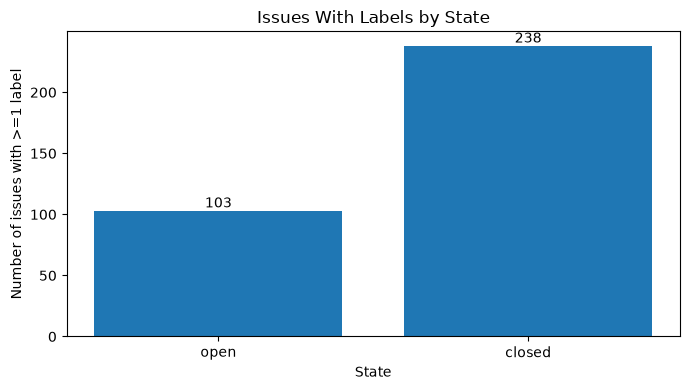

In [19]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import openpyxl
# Load corpus
with open("data/corpus.json", "r", encoding="utf-8") as f:
    corpus = json.load(f)

issues = corpus["issues"]

# Count issues with >=1 maintainer label by state
counts = {"open": 0, "closed": 0}
totals = {"open": 0, "closed": 0}

for issue in issues:
    state = issue.get("state")
    if state not in counts:
        continue
    totals[state] += 1
    labels = issue.get("maintainer_labels") or []
    if len(labels) > 0:
        counts[state] += 1

print("Open issues with labels:", counts["open"], "out of", totals["open"], " Coverage:", round(counts["open"]/totals["open"]*100,2), "%")
print("Closed issues with labels:", counts["closed"], "out of", totals["closed"], " Coverage:", round(counts["closed"]/totals["closed"]*100,2), "%")

# Bar chart
states = ["open", "closed"]
values = [counts["open"], counts["closed"]]

plt.figure(figsize=(7, 4))
bars = plt.bar(states, values)
plt.title("Issues With Labels by State")
plt.xlabel("State")
plt.ylabel("Number of issues with >=1 label")

# Value labels on bars
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(value),
             ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [20]:
df = pd.DataFrame(corpus.get("issues", []))

# Filter comments_count > 1 and keep required columns
result = df.loc[
    df["comments_count"].fillna(0).gt(1),
    ["issue_id", "title", "body", "state", "maintainer_labels", "created_at", "closed_at","comments_count", "url"]
].copy()

# Optional: sort by most commented
result = result.sort_values("comments_count", ascending=False).reset_index(drop=True)

print("Rows:", len(result))
display(result.head(20))

Rows: 316


,issue_id,title,body,state,maintainer_labels,created_at,closed_at,comments_count,url
0,733,Errors when using Git for Windows,"**Doctl says unknown terminal, when trying `do...",open,"[bug, Needs Investigation]",2020-01-30T23:51:57Z,NaN,20,https://github.com/digitalocean/doctl/issues/733
1,630,create droplet in a specific project,"digitalocean can group droplets into ""projects...",closed,"[enhancement, do-api]",2019-10-04T11:25:01Z,2024-01-26T16:21:07Z,19,https://github.com/digitalocean/doctl/issues/630
2,19,Can't login on windows,Just tried installing the client after the twi...,closed,[],2016-03-30T15:54:38Z,2016-06-08T02:47:36Z,14,https://github.com/digitalocean/doctl/issues/19
3,1345,"""Unexpected end Of JSON input"" error doing `do...",**Describe the Issue:**\r\n\r\n<!-- Please pro...,open,"[bug, Needs Investigation]",2023-01-24T03:59:10Z,NaN,13,https://github.com/digitalocean/doctl/issues/1345
4,47,Add a FreeBSD release,I would like to make a FreeBSD port for the do...,closed,[],2016-04-11T15:06:43Z,2018-03-07T22:16:31Z,13,https://github.com/digitalocean/doctl/issues/47
5,311,Make doctl available as a Flatpak,Since Flatpak is more or less the native app c...,open,"[suggestion, packaging]",2018-05-01T12:02:19Z,NaN,12,https://github.com/digitalocean/doctl/issues/311
6,390,updating the snap,snap find doctl\r\n\r\nName Version Publish...,closed,"[wip, packaging, snap]",2019-01-08T19:12:24Z,2019-06-20T17:35:02Z,12,https://github.com/digitalocean/doctl/issues/390
7,877,Error: neither $XDG_CONFIG_HOME nor $HOME are ...,**Describe the Issue:**\r\n\r\nAttempt to run ...,open,"[bug, snap, Needs Investigation]",2020-10-08T01:46:20Z,NaN,12,https://github.com/digitalocean/doctl/issues/877
8,216,accept name of ssh key when specifying --ssh-k...,Having to find the fingerprint and provide tha...,closed,[],2017-04-17T21:27:41Z,2017-05-17T18:58:34Z,11,https://github.com/digitalocean/doctl/issues/216
9,42,"plain ""go get"" doesn't work on the repository",`$ go get github.com/digitalocean/doctl/cmd/do...,closed,[],2016-04-10T19:54:30Z,2017-04-04T19:34:01Z,11,https://github.com/digitalocean/doctl/issues/42


In [24]:
import re
import pandas as pd

# Excel-invalid control chars
_illegal = re.compile(r"[\x00-\x08\x0B-\x0C\x0E-\x1F]")

def clean_excel_value(v):
    if isinstance(v, str):
        return _illegal.sub("", v)
    if isinstance(v, list):
        return ", ".join(str(x) for x in v)  # labels list -> one cell
    if isinstance(v, dict):
        return str(v)
    return v

# Ensure df is a DataFrame
df = pd.DataFrame(df)

# Element-wise clean (new pandas)
df_clean = df.map(clean_excel_value)

# Export
output_path = "data/corpus.xlsx"
df_clean.to_excel(output_path, index=False, engine="openpyxl")
print(f"Excel created: {output_path}")

Excel created: data/corpus.xlsx


In [25]:
import pandas as pd
import json
from pathlib import Path

input_path = Path(r"C:\Users\sasalgaonkar\repo\digital_ocean_assignment\data\corpus_golden_labeled.xlsx")
output_path = input_path.with_suffix(".json")

# Read Excel
df = pd.read_excel(input_path)

# Optional cleanup: convert NaN to None for valid JSON nulls
records = df.where(pd.notnull(df), None).to_dict(orient="records")

# Write JSON
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(records, f, ensure_ascii=False, indent=2)

print(f"JSON created: {output_path}")

JSON created: C:\Users\sasalgaonkar\repo\digital_ocean_assignment\data\corpus_golden_labeled.json


In [26]:
import json
from pathlib import Path

input_path = Path(r"C:\Users\sasalgaonkar\repo\digital_ocean_assignment\data\corpus_golden_labeled.json")
output_path = input_path.with_name("corpus_golden_labeled_scored_only.json")

with open(input_path, "r", encoding="utf-8") as f:
    data = json.load(f)

# Handle both:
# 1) list of records
# 2) {"meta": ..., "issues": [...]}
if isinstance(data, dict) and isinstance(data.get("issues"), list):
    records = data["issues"]
    scored_only = [r for r in records if r.get("is_scored") is True]
    result = {"issues": scored_only}
elif isinstance(data, list):
    scored_only = [r for r in data if r.get("is_scored") is True]
    result = scored_only
else:
    raise ValueError("Unexpected JSON structure")

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(result, f, ensure_ascii=False, indent=2)

print(f"Total scored rows: {len(scored_only)}")
print(f"Written: {output_path}")

Total scored rows: 159
Written: C:\Users\sasalgaonkar\repo\digital_ocean_assignment\data\corpus_golden_labeled_scored_only.json
